In [1]:
import duckdb

con = duckdb.connect("tracking_analysis.duckdb")

parquet_glob = ("track_amazon_lluc/tracking_table/monthly/*.parquet")

con.execute(f"""
    CREATE OR REPLACE VIEW TRACK_TABLE AS
    SELECT *
    FROM read_parquet('{parquet_glob}', union_by_name=true)
""")

In [26]:
con.execute("""
CREATE OR REPLACE TEMP TABLE FOREST_SYSTEMS_2H AS

WITH UID_STATS AS (
    SELECT
        uid,

        MIN(timestamp) AS first_timestamp,

        -- Duration in hours
        MAX(duration) FILTER (
            WHERE isfinite(duration)
        ) / 60.0 AS duration_hr,

        -- Forest classification
        COUNT(*) AS n_records,

        COUNT(*) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS n_valid_forest,

        MIN(Floresta_mean) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS min_forest,

        -- Mean size across the lifetime of each UID
        AVG(size) FILTER (
            WHERE isfinite(size)
        ) AS mean_size,

        -- Mean rain rate across the lifetime of each UID
        AVG("mean") FILTER (
            WHERE isfinite("mean")
        ) AS mean_rain_rate

    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
    GROUP BY uid
),

QUALIFIED AS (
    SELECT
        uid,
        first_timestamp,
        duration_hr,
        min_forest,
        mean_size,
        mean_rain_rate,

        -- Equivalent radius in km
        SQRT((mean_size * 100.0) / PI()) AS radius_km

    FROM UID_STATS

    WHERE
        duration_hr > 2
        AND n_valid_forest = n_records
        AND min_forest >= 0.99
)

SELECT *
FROM QUALIFIED;
""")

print("Forest systems table created!")

Forest systems table created!


In [27]:
result = con.execute("""
SELECT
    COUNT(*) AS n_systems,
    COUNT(radius_km) AS n_with_radius,
    COUNT(mean_rain_rate) AS n_with_rain_rate,
    MIN(first_timestamp) AS first_date,
    MAX(first_timestamp) AS last_date
FROM FOREST_SYSTEMS_2H
""").df()

display(result)

,n_systems,n_with_radius,n_with_rain_rate,first_date,last_date
0,19463,19463,19463,1998-01-01,2024-12-31 04:00:00


In [28]:
df_monthly = con.execute("""
SELECT
    DATE_TRUNC('month', first_timestamp)::DATE AS month,

    -- Number of unique systems
    COUNT(*) AS n_systems,

    -- Duration
    AVG(duration_hr) AS mean_duration,
    MEDIAN(duration_hr) AS median_duration,
    STDDEV(duration_hr) AS std_duration,

    -- Equivalent radius
    AVG(radius_km) AS mean_radius,
    MEDIAN(radius_km) AS median_radius,
    STDDEV(radius_km) AS std_radius,

    -- Mean rain rate
    AVG(mean_rain_rate) AS mean_rain_rate,
    MEDIAN(mean_rain_rate) AS median_rain_rate,
    STDDEV(mean_rain_rate) AS std_rain_rate,

    COUNT(radius_km) AS n_radius,
    COUNT(mean_rain_rate) AS n_rain_rate

FROM FOREST_SYSTEMS_2H

GROUP BY 1
ORDER BY 1
""").df()

df_monthly["month"] = pd.to_datetime(df_monthly["month"])

display(df_monthly.head())

,month,n_systems,mean_duration,median_duration,std_duration,mean_radius,median_radius,std_radius,mean_rain_rate,median_rain_rate,std_rain_rate,n_radius,n_rain_rate
0,1998-01-01,123,3.581301,3.0,1.309445,20.688656,18.062880,9.231469,0.709772,0.567831,0.470075,123,123
1,1998-02-01,74,3.331081,3.0,1.285528,22.321022,19.110130,11.285317,0.644603,0.604002,0.331016,74,74
2,1998-03-01,102,3.700980,3.5,1.313034,21.538348,17.356742,10.323308,0.735150,0.682804,0.360481,102,102
3,1998-04-01,109,3.380734,3.0,1.233970,23.038977,20.342145,10.371300,0.761209,0.670226,0.467228,109,109
4,1998-05-01,97,3.396907,3.0,1.087184,19.887787,18.426355,7.590041,0.764261,0.689976,0.383453,97,97


In [37]:
df_monthly = con.execute("""
SELECT
    DATE_TRUNC('month', first_timestamp)::DATE AS month,

    -- Number of unique systems
    COUNT(*) AS n_systems,

    -- Duration: one value per UID
    AVG(duration_hr) AS mean_duration,
    STDDEV_SAMP(duration_hr) AS std_duration,

    -- Equivalent radius: one value per UID
    AVG(radius_km) AS mean_radius,
    STDDEV_SAMP(radius_km) AS std_radius,

    -- Rain rate: one value per UID
    AVG(mean_rain_rate) AS mean_rain_rate,
    STDDEV_SAMP(mean_rain_rate) AS std_rain_rate,

    -- Number of valid UIDs for each variable
    COUNT(radius_km) AS n_radius,
    COUNT(mean_rain_rate) AS n_rain_rate

FROM FOREST_SYSTEMS_2H
GROUP BY 1
ORDER BY 1
""").df()

df_monthly["month"] = pd.to_datetime(df_monthly["month"])
df_monthly = df_monthly.set_index("month")

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_monthly = df_monthly.sort_values("month").set_index("month")

variables = {
    "n_systems": "Number of systems",
    "mean_duration": "Mean duration (hours)",
    "mean_radius": "Mean equivalent radius (km)",
    "mean_rain_rate": "Mean rain rate"
}

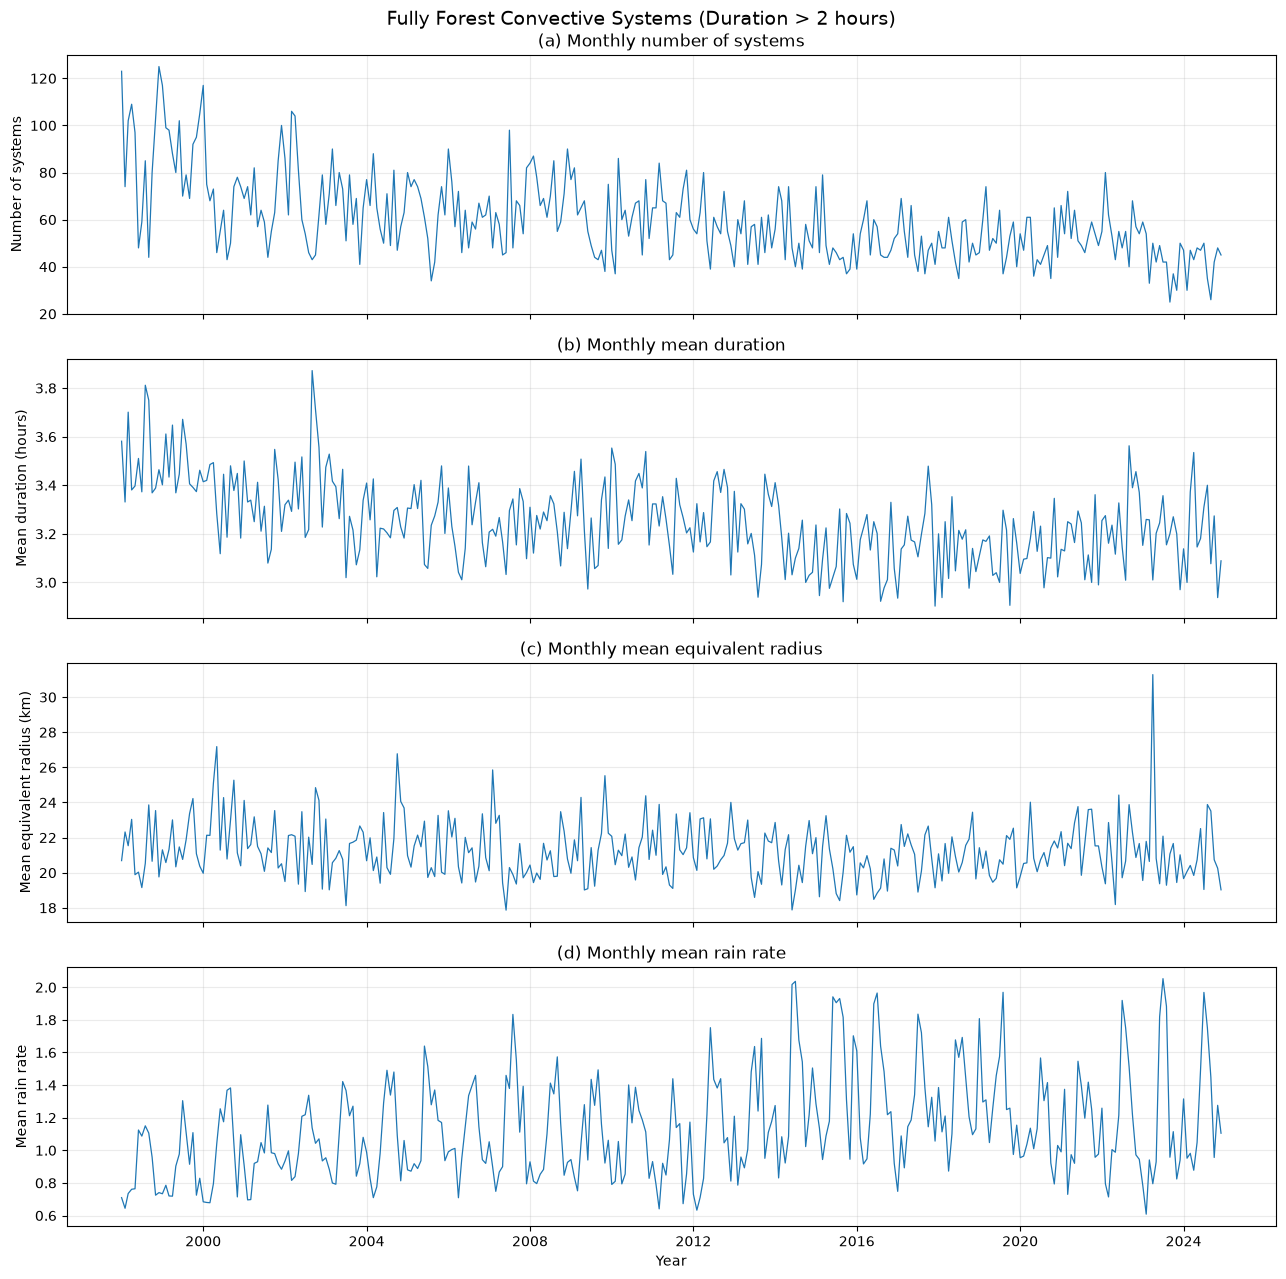

In [30]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 13),
    sharex=True
)

for ax, (variable, ylabel) in zip(axes, variables.items()):

    ax.plot(
        df_monthly.index,
        df_monthly[variable],
        linewidth=0.9
    )

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)

axes[0].set_title("(a) Monthly number of systems")
axes[1].set_title("(b) Monthly mean duration")
axes[2].set_title("(c) Monthly mean equivalent radius")
axes[3].set_title("(d) Monthly mean rain rate")

axes[-1].set_xlabel("Year")

fig.suptitle(
    "Fully Forest Convective Systems (Duration > 2 hours)",
    fontsize=14
)

plt.tight_layout()
plt.show()

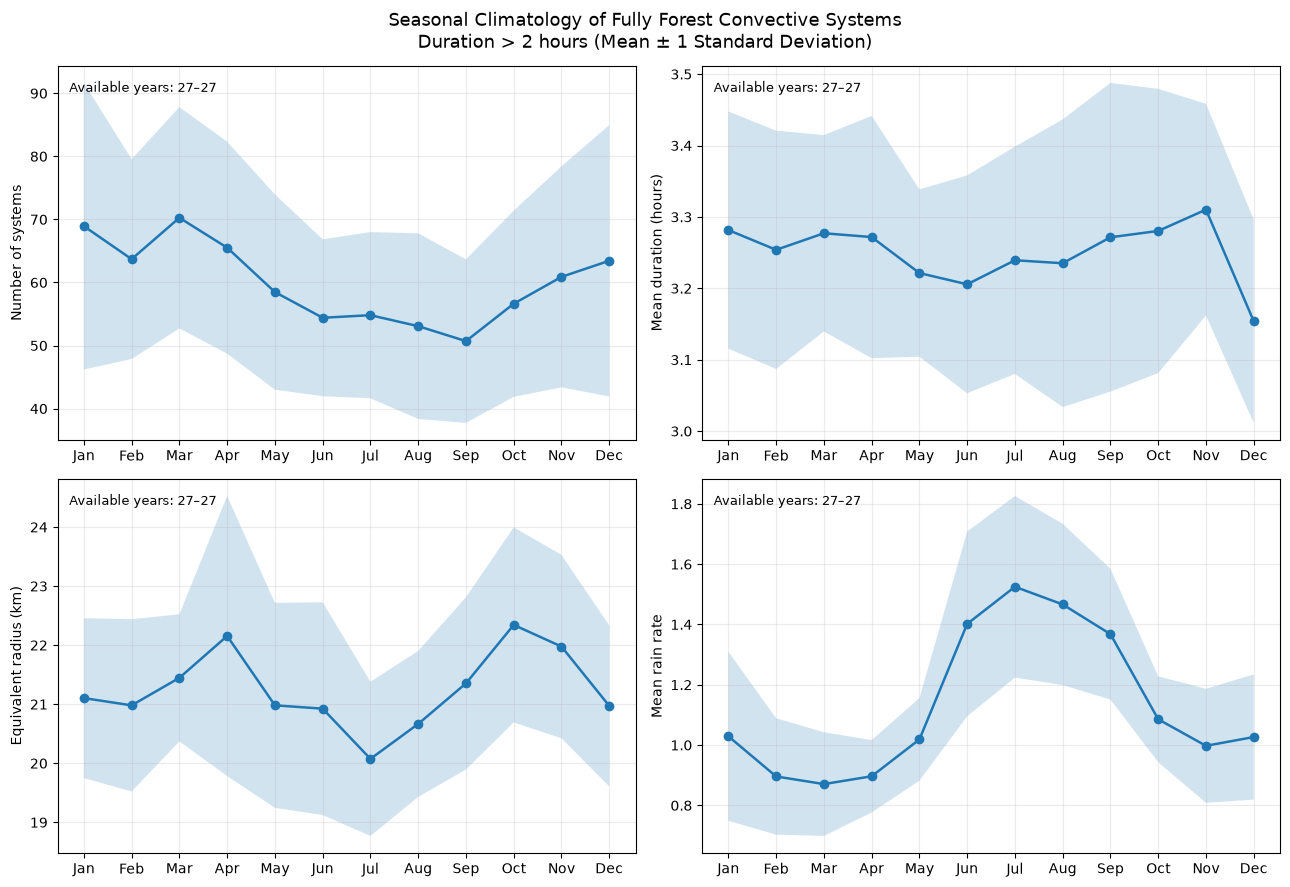

In [35]:
import matplotlib.pyplot as plt

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plot_variables = [
    ("n_systems", "Number of systems"),
    ("mean_duration", "Mean duration (hours)"),
    ("mean_radius", "Equivalent radius (km)"),
    ("mean_rain_rate", "Mean rain rate")
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

for ax, (variable, ylabel) in zip(
    axes.flat, plot_variables
):

    # Climatological monthly mean and standard deviation
    monthly_mean = (
        df_complete[variable]
        .groupby(df_complete.index.month)
        .mean()
        .reindex(range(1, 13))
    )

    monthly_std = (
        df_complete[variable]
        .groupby(df_complete.index.month)
        .std()
        .reindex(range(1, 13))
    )

    monthly_n = (
        df_complete[variable]
        .groupby(df_complete.index.month)
        .count()
        .reindex(range(1, 13))
    )

    x = np.arange(1, 13)

    ax.plot(
        x,
        monthly_mean,
        marker="o",
        linewidth=1.8
    )

    ax.fill_between(
        x,
        monthly_mean - monthly_std,
        monthly_mean + monthly_std,
        alpha=0.2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(month_labels)

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)

    # Show sample size for each calendar month
    ax.text(
        0.02, 0.96,
        f"Available years: {monthly_n.min()}–{monthly_n.max()}",
        transform=ax.transAxes,
        va="top",
        fontsize=9
    )

fig.suptitle(
    "Seasonal Climatology of Fully Forest Convective Systems\n"
    "Duration > 2 hours (Mean ± 1 Standard Deviation)",
    fontsize=13
)

plt.tight_layout()
plt.show()

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# --------------------------------------------------
# PREPARE MONTHLY DATA
# --------------------------------------------------

df_stl = df_monthly.copy()

if "month" in df_stl.columns:
    df_stl["month"] = pd.to_datetime(df_stl["month"])
    df_stl = df_stl.set_index("month")

df_stl = df_stl.sort_index()

# Full monthly calendar, without interpolation
full_index = pd.date_range(
    start=df_stl.index.min(),
    end=df_stl.index.max(),
    freq="MS"
)

df_stl = df_stl.reindex(full_index)
df_stl.index.name = "month"

variables = [
    "n_systems",
    "mean_duration",
    "mean_radius",
    "mean_rain_rate"
]

# Check missing months for each variable
print("Missing monthly observations:")
print(df_stl[variables].isna().sum())

print("\nNumber of complete monthly observations:")
print(df_stl[variables].notna().sum())

print("\nMissing months:")
print(df_stl.index[df_stl[variables].isna().any(axis=1)])

Missing monthly observations:
n_systems         0
mean_duration     0
mean_radius       0
mean_rain_rate    0
dtype: int64

Number of complete monthly observations:
n_systems         324
mean_duration     324
mean_radius       324
mean_rain_rate    324
dtype: int64

Missing months:
DatetimeIndex([], dtype='datetime64[us]', name='month', freq='MS')


In [44]:
# --------------------------------------------------
# STL DECOMPOSITION
# --------------------------------------------------

stl_results = {}

for variable in variables:

    series = df_stl[variable].astype(float)

    # Skip variables with missing observations
    if series.isna().any():
        print(f"Skipping {variable}: missing monthly observations.")
        continue

    # Robust STL decomposition
    stl = STL(
        series,
        period=12,
        robust=True
    )

    result = stl.fit()

    stl_results[variable] = result

    print(f"STL completed: {variable}")

STL completed: n_systems
STL completed: mean_duration
STL completed: mean_radius
STL completed: mean_rain_rate


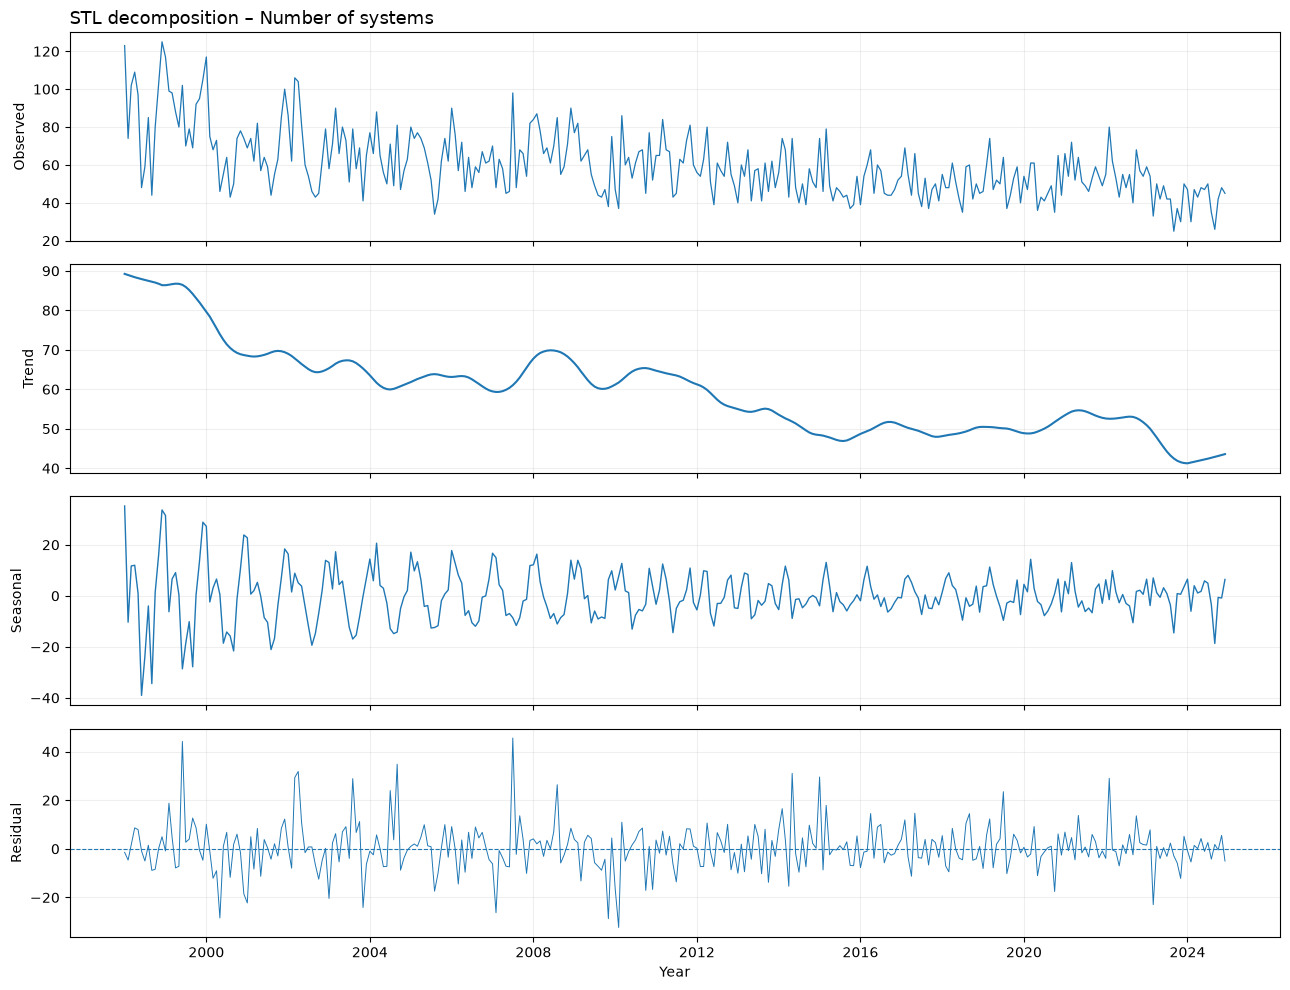

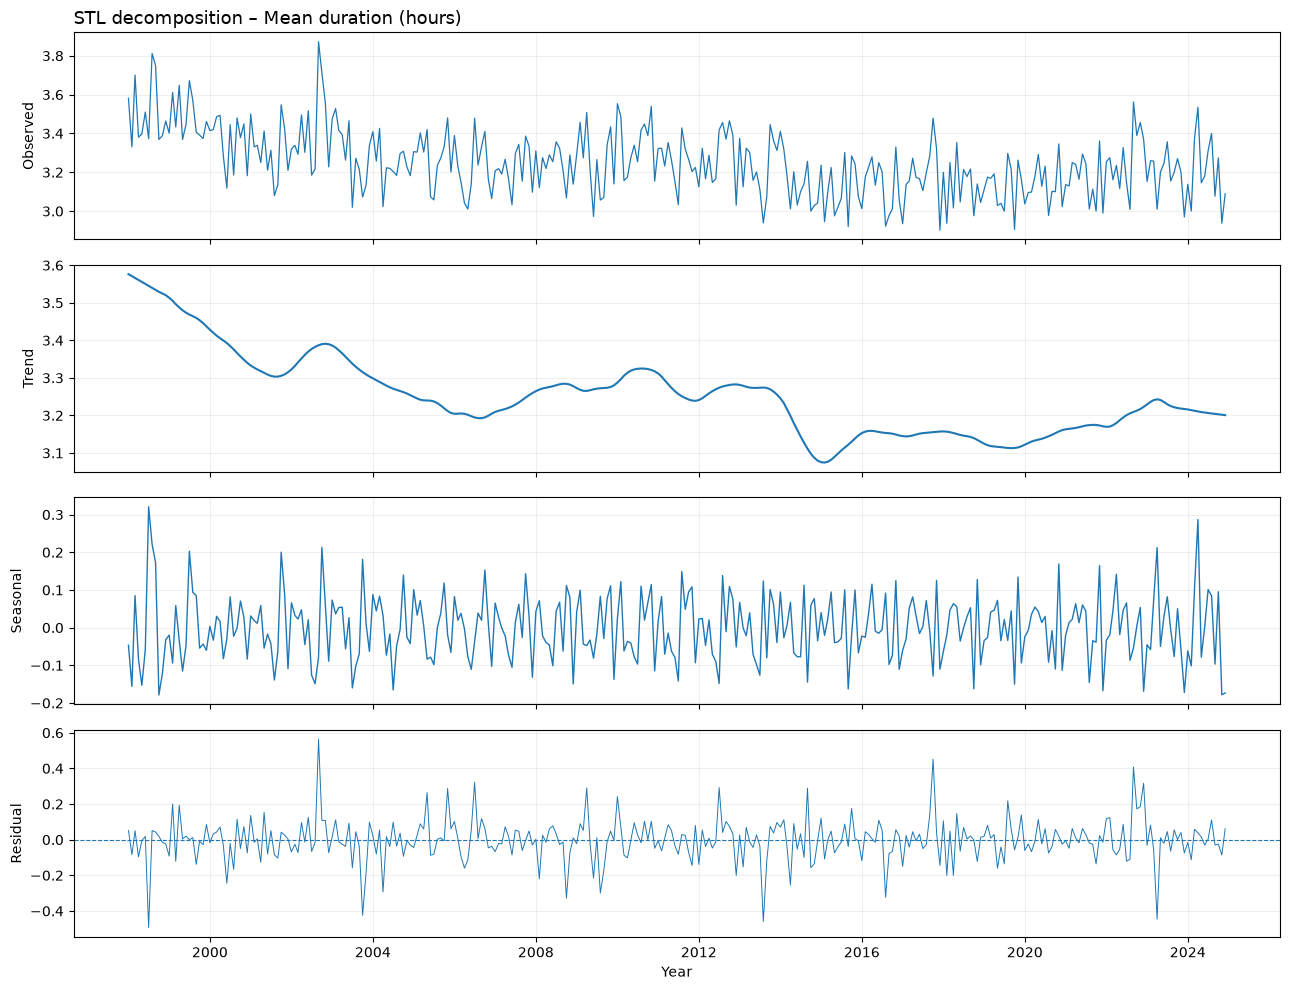

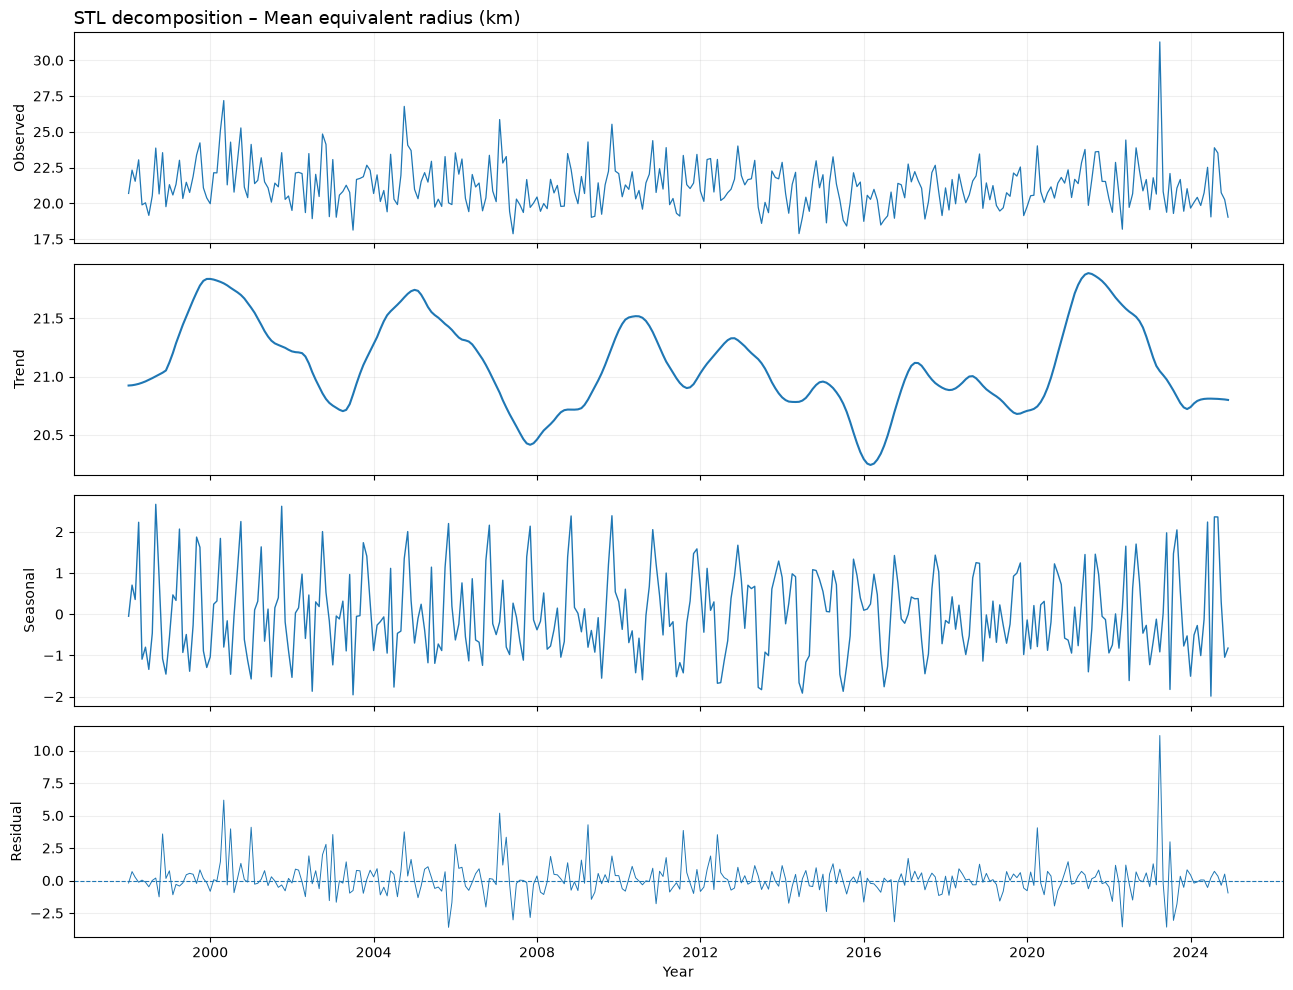

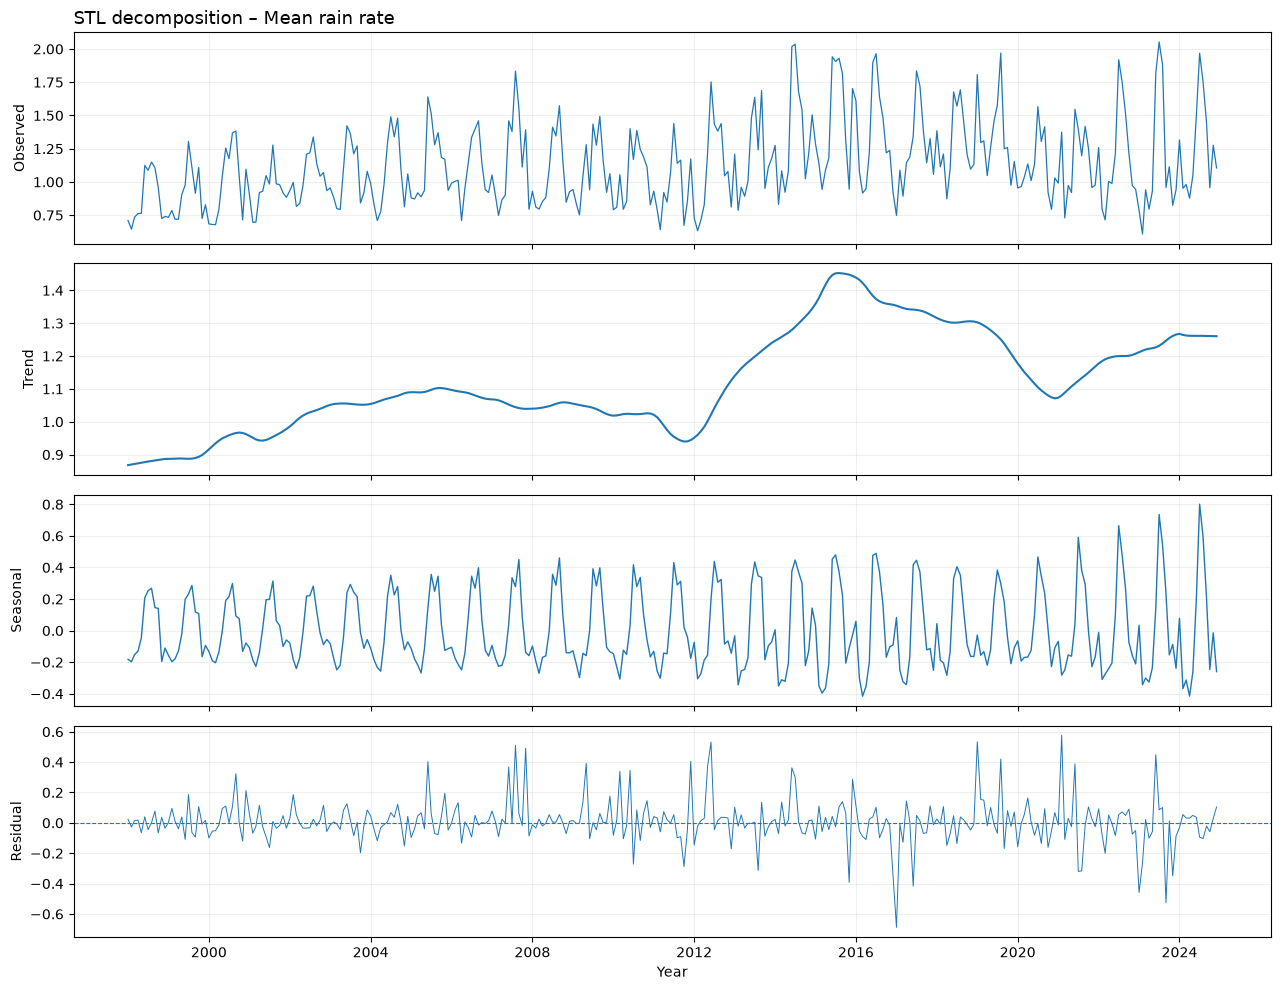

In [45]:
# --------------------------------------------------
# PLOT STL COMPONENTS
# --------------------------------------------------

variable_labels = {
    "n_systems": "Number of systems",
    "mean_duration": "Mean duration (hours)",
    "mean_radius": "Mean equivalent radius (km)",
    "mean_rain_rate": "Mean rain rate"
}

for variable, result in stl_results.items():

    fig, axes = plt.subplots(
        4, 1,
        figsize=(13, 10),
        sharex=True
    )

    # Observed
    axes[0].plot(
        result.observed.index,
        result.observed,
        linewidth=0.9
    )
    axes[0].set_ylabel("Observed")
    axes[0].set_title(
        f"STL decomposition – {variable_labels[variable]}",
        loc="left",
        fontsize=13
    )

    # Trend
    axes[1].plot(
        result.trend.index,
        result.trend,
        linewidth=1.5
    )
    axes[1].set_ylabel("Trend")

    # Seasonal
    axes[2].plot(
        result.seasonal.index,
        result.seasonal,
        linewidth=1.0
    )
    axes[2].set_ylabel("Seasonal")

    # Residual
    axes[3].plot(
        result.resid.index,
        result.resid,
        linewidth=0.7
    )
    axes[3].axhline(0, linestyle="--", linewidth=0.8)
    axes[3].set_ylabel("Residual")
    axes[3].set_xlabel("Year")

    for ax in axes:
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

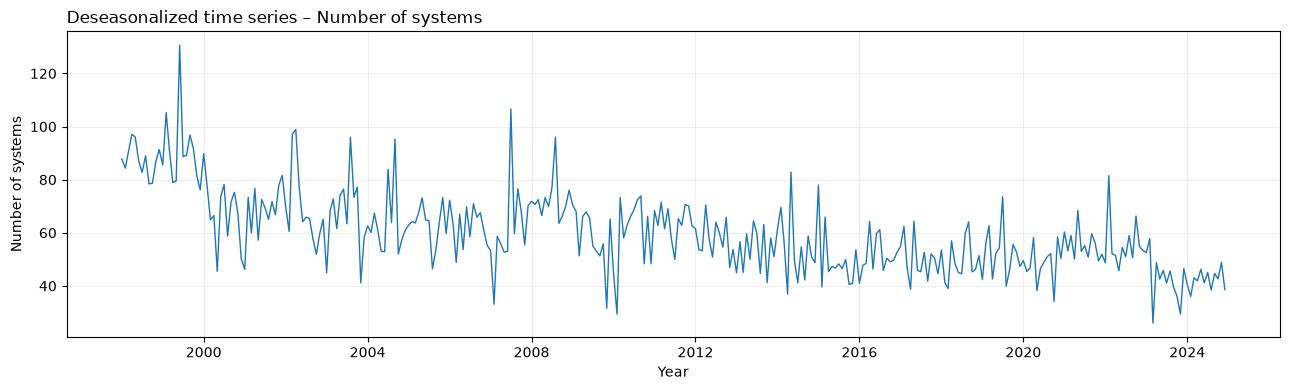

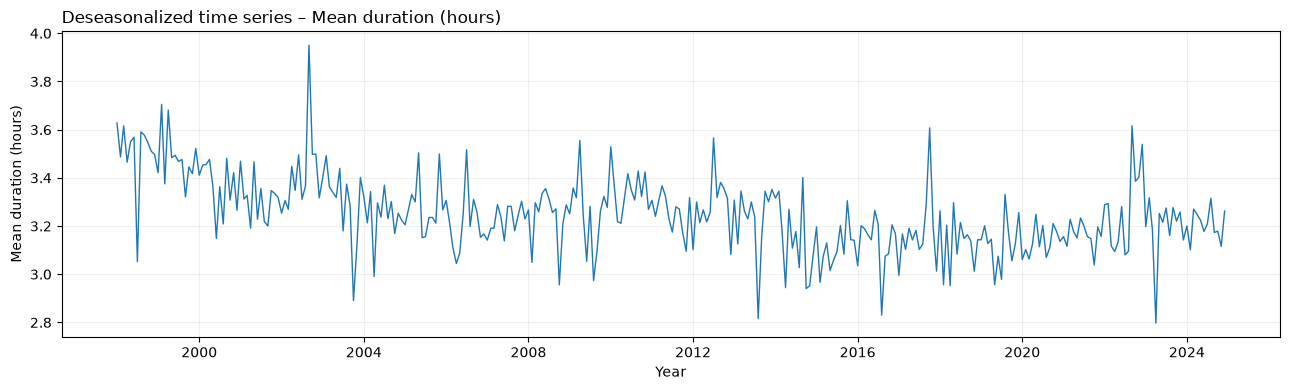

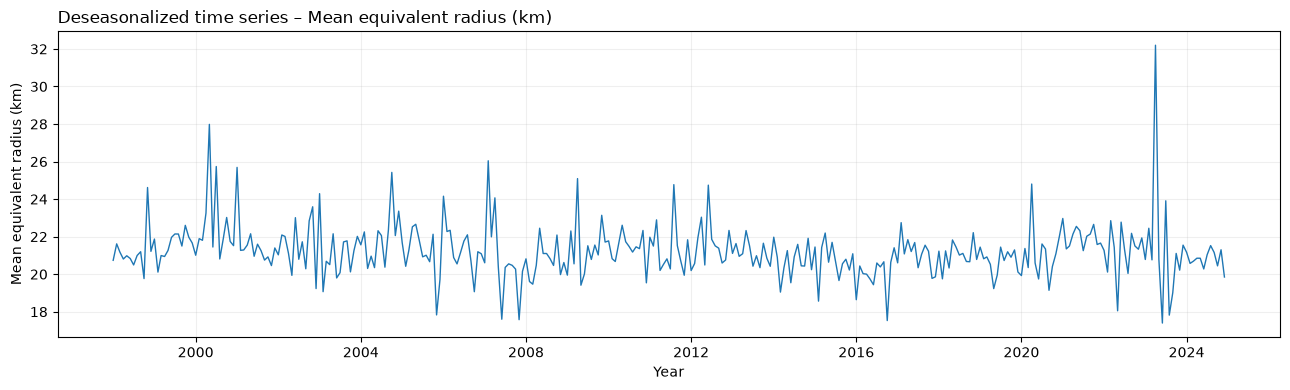

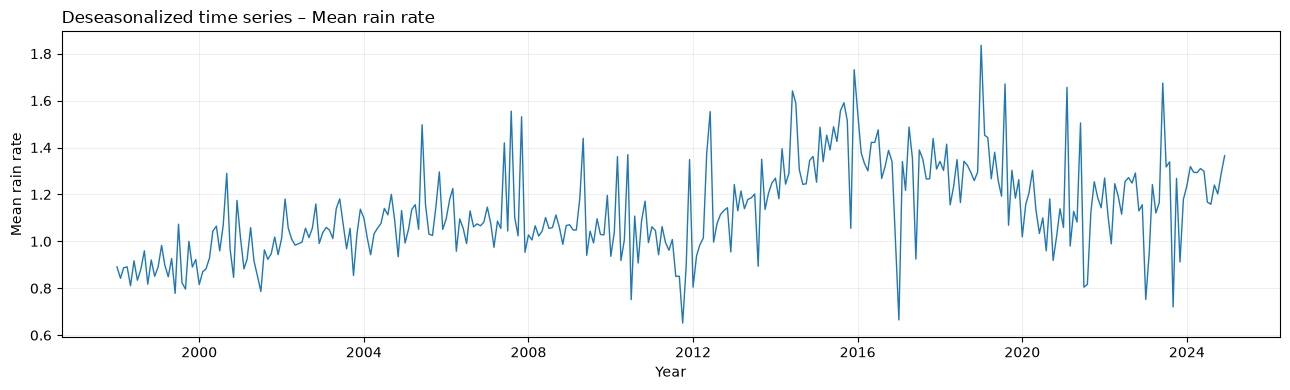

In [46]:
# --------------------------------------------------
# DESEASONALIZED SERIES
# --------------------------------------------------

deseasonalized = {}

for variable, result in stl_results.items():

    deseasonalized[variable] = (
        result.observed - result.seasonal
    )

    plt.figure(figsize=(13, 4))

    plt.plot(
        deseasonalized[variable].index,
        deseasonalized[variable],
        linewidth=1
    )

    plt.title(
        f"Deseasonalized time series – {variable_labels[variable]}",
        loc="left"
    )

    plt.ylabel(variable_labels[variable])
    plt.xlabel("Year")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

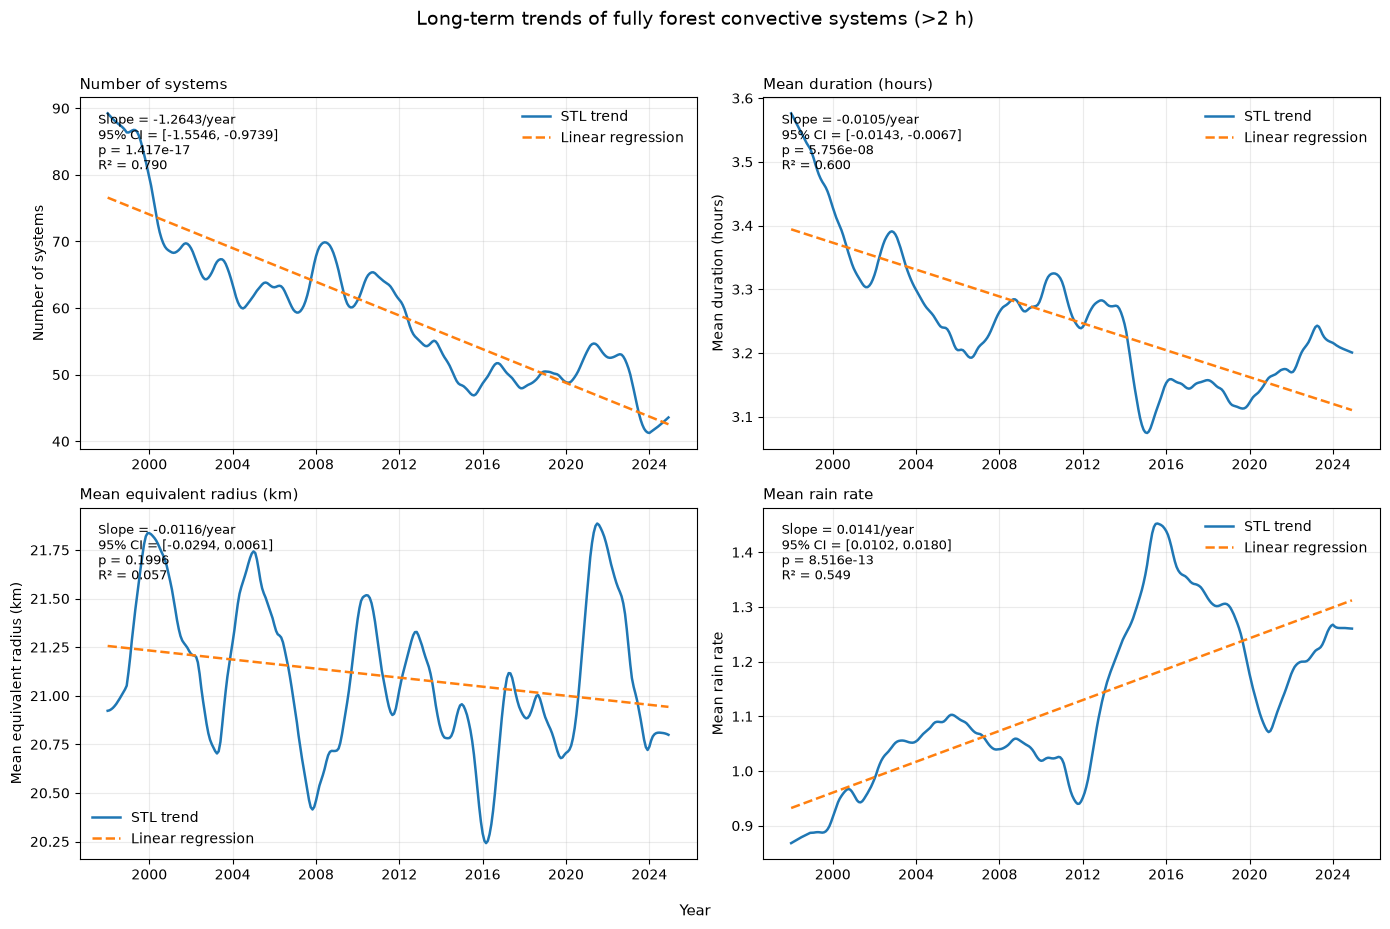

,slope_per_year,ci_lower,ci_upper,p_value,r_squared
n_systems,-1.26427,-1.55464,-0.97390,0.00000,0.79004
mean_duration,-0.01054,-0.01435,-0.00673,0.00000,0.59994
mean_radius,-0.01164,-0.02942,0.00614,0.19956,0.05695
mean_rain_rate,0.01411,0.01024,0.01797,0.00000,0.54900


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL

# --------------------------------------------------
# PREPARE DATA
# --------------------------------------------------

df_stl = df_monthly.copy()

if "month" in df_stl.columns:
    df_stl["month"] = pd.to_datetime(df_stl["month"])
    df_stl = df_stl.set_index("month")

df_stl = df_stl.sort_index()

variables = {
    "n_systems": "Number of systems",
    "mean_duration": "Mean duration (hours)",
    "mean_radius": "Mean equivalent radius (km)",
    "mean_rain_rate": "Mean rain rate"
}

# Check monthly continuity
full_index = pd.date_range(
    start=df_stl.index.min(),
    end=df_stl.index.max(),
    freq="MS"
)

df_stl = df_stl.reindex(full_index)

if df_stl[list(variables)].isna().any().any():
    raise ValueError("Missing monthly values detected.")

# --------------------------------------------------
# STL + REGRESSION
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

axes = axes.flatten()

trend_statistics = {}

for ax, (variable, label) in zip(axes, variables.items()):

    series = df_stl[variable].astype(float)

    # STL decomposition
    result = STL(
        series,
        period=12,
        robust=True
    ).fit()

    dates = result.trend.index

    # Time in years
    x_years = (
        (dates - dates[0]).days / 365.2425
    )

    X = sm.add_constant(x_years)

    # HAC regression on STL trend
    model = sm.OLS(
        result.trend.values,
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 12}
    )

    regression_line = model.predict(X)

    slope = model.params[1]
    p_value = model.pvalues[1]
    r_squared = model.rsquared
    ci_low, ci_high = model.conf_int()[1]

    trend_statistics[variable] = {
        "slope_per_year": slope,
        "ci_lower": ci_low,
        "ci_upper": ci_high,
        "p_value": p_value,
        "r_squared": r_squared
    }

    # Plot STL trend
    ax.plot(
        dates,
        result.trend,
        linewidth=1.8,
        label="STL trend"
    )

    # Plot regression
    ax.plot(
        dates,
        regression_line,
        linestyle="--",
        linewidth=1.8,
        label="Linear regression"
    )

    ax.set_title(label, loc="left", fontsize=11)
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)

    # Statistics
    ax.text(
        0.03, 0.96,
        (
            f"Slope = {slope:.4f}/year\n"
            f"95% CI = [{ci_low:.4f}, {ci_high:.4f}]\n"
            f"p = {p_value:.4g}\n"
            f"R² = {r_squared:.3f}"
        ),
        transform=ax.transAxes,
        va="top",
        fontsize=9
    )

    ax.legend(frameon=False, loc="best")

fig.supxlabel("Year", fontsize=11)

fig.suptitle(
    "Long-term trends of fully forest convective systems (>2 h)",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.savefig(
    "STL_trends_fully_forest_2h.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# SUMMARY TABLE
# --------------------------------------------------

df_trend_statistics = pd.DataFrame(trend_statistics).T

display(df_trend_statistics.round(5))

In [54]:

# ============================================================
# FOREST COVER DISTRIBUTION
# Systems with duration > 2 hours
# One observation per UID
# ============================================================

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate UID-level forest cover
df_forest = con.execute("""
WITH UID_STATS AS (
    SELECT
        uid,

        MAX(duration) FILTER (
            WHERE isfinite(duration)
        ) / 60.0 AS duration_hr,

        AVG(Floresta_mean) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS forest_mean,

        COUNT(*) AS n_records,

        COUNT(*) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS n_valid_forest

    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
    GROUP BY uid
)

SELECT
    uid,
    duration_hr,
    forest_mean

FROM UID_STATS

WHERE duration_hr > 2
  AND n_valid_forest = n_records
  AND n_valid_forest > 0
""").df()

print(f"Number of systems: {len(df_forest):,}")
print(df_forest["forest_mean"].describe())


Number of systems: 1,868,386
count    1.868386e+06
mean     5.453988e-01
std      3.336007e-01
min      0.000000e+00
25%      1.853888e-01
50%      5.976777e-01
75%      8.718558e-01
max      1.000000e+00
Name: forest_mean, dtype: float64


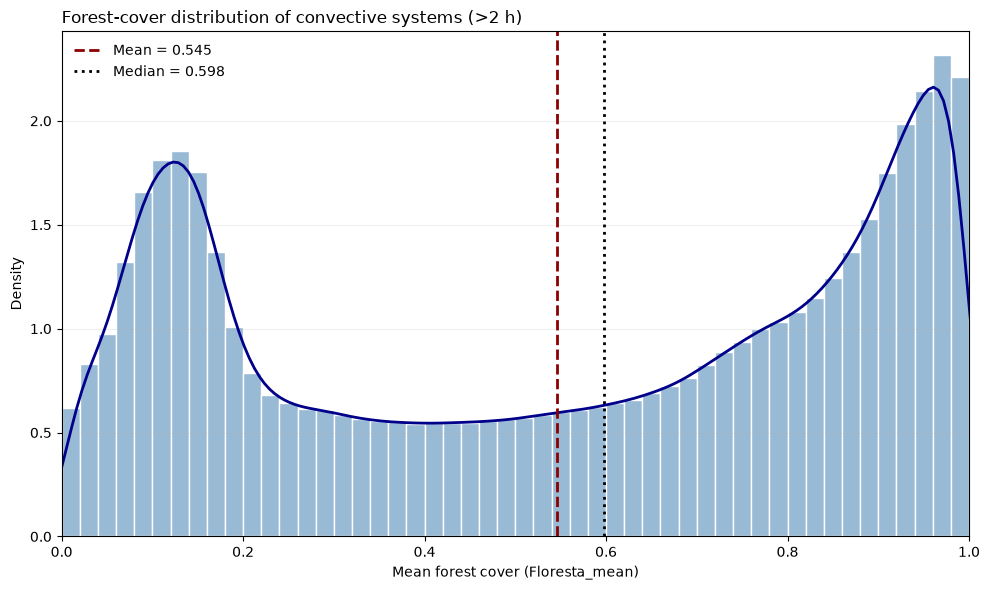

In [55]:

# ============================================================
# HISTOGRAM + KDE
# ============================================================

values = df_forest["forest_mean"].dropna()

mean_value = values.mean()
median_value = values.median()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    values,
    bins=50,
    stat="density",
    color="steelblue",
    alpha=0.55,
    edgecolor="white",
    ax=ax
)

sns.kdeplot(
    values,
    color="darkblue",
    linewidth=2,
    ax=ax
)

ax.axvline(
    mean_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.3f}"
)

ax.axvline(
    median_value,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_value:.3f}"
)

ax.set_xlabel("Mean forest cover (Floresta_mean)")
ax.set_ylabel("Density")
ax.set_title(
    "Forest-cover distribution of convective systems (>2 h)",
    loc="left"
)

ax.set_xlim(0, 1)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    "forest_cover_distribution_duration_gt2h.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [56]:

# ============================================================
# FOREST COVER CATEGORIES
# ============================================================

bins = [0, 0.25, 0.50, 0.75, 1.01]

labels = [
    "0–0.25",
    "0.25–0.50",
    "0.50–0.75",
    "0.75–1.00"
]

df_forest["forest_category"] = pd.cut(
    df_forest["forest_mean"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False
)

df_categories = (
    df_forest["forest_category"]
    .value_counts(sort=False)
    .rename("n_systems")
    .to_frame()
)

df_categories["percentage"] = (
    df_categories["n_systems"]
    / len(df_forest) * 100
)

display(df_categories.round(2))


,n_systems,percentage
forest_category,,
0–0.25,560288,29.99
0.25–0.50,265076,14.19
0.50–0.75,322466,17.26
0.75–1.00,720556,38.57


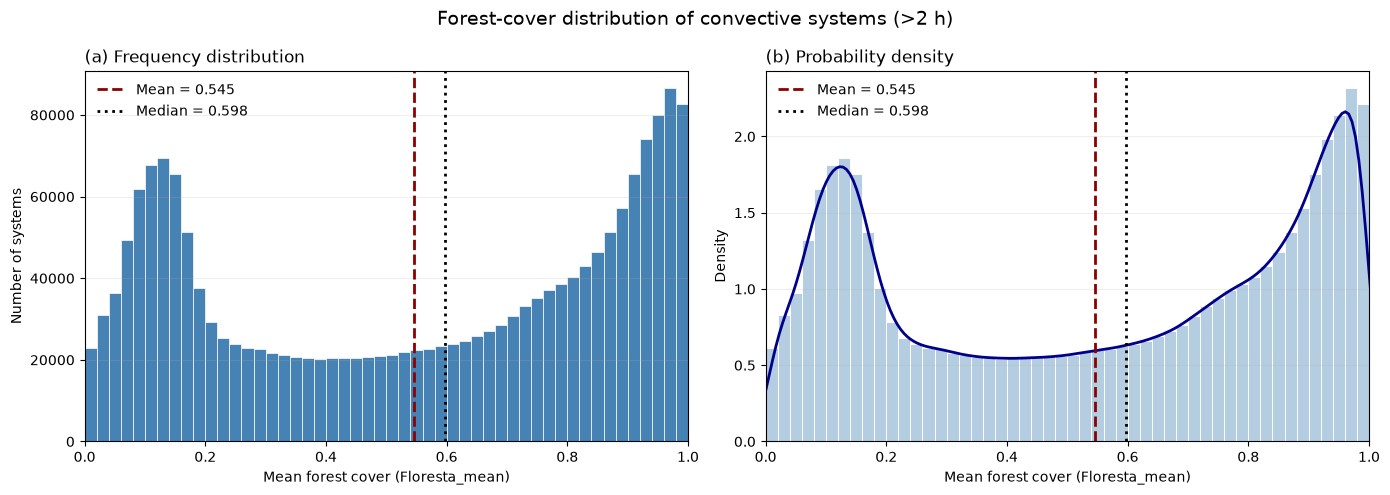

In [57]:

# ============================================================
# FOREST COVER FREQUENCY DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

values = df_forest["forest_mean"].dropna()

mean_value = values.mean()
median_value = values.median()

# ------------------------------------------------------------
# (a) Frequency histogram
# ------------------------------------------------------------

axes[0].hist(
    values,
    bins=np.linspace(0, 1, 51),
    color="steelblue",
    edgecolor="white",
    linewidth=0.5
)

axes[0].axvline(
    mean_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.3f}"
)

axes[0].axvline(
    median_value,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_value:.3f}"
)

axes[0].set_xlabel("Mean forest cover (Floresta_mean)")
axes[0].set_ylabel("Number of systems")
axes[0].set_title("(a) Frequency distribution", loc="left")
axes[0].set_xlim(0, 1)
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2)

# ------------------------------------------------------------
# (b) Probability density distribution
# ------------------------------------------------------------

sns.histplot(
    values,
    bins=50,
    stat="density",
    color="steelblue",
    alpha=0.4,
    edgecolor="white",
    ax=axes[1]
)

sns.kdeplot(
    values,
    color="darkblue",
    linewidth=2,
    ax=axes[1]
)

axes[1].axvline(
    mean_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.3f}"
)

axes[1].axvline(
    median_value,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_value:.3f}"
)

axes[1].set_xlabel("Mean forest cover (Floresta_mean)")
axes[1].set_ylabel("Density")
axes[1].set_title("(b) Probability density", loc="left")
axes[1].set_xlim(0, 1)
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Forest-cover distribution of convective systems (>2 h)",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "forest_cover_frequency_distribution_gt2h.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [58]:

# ============================================================
# FOREST COVER DISTRIBUTION - ALL SYSTEMS
# One observation per UID, no duration restriction
# ============================================================

df_forest_all = con.execute("""
WITH UID_STATS AS (
    SELECT
        uid,

        MAX(duration) FILTER (
            WHERE isfinite(duration)
        ) / 60.0 AS duration_hr,

        AVG(Floresta_mean) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS forest_mean,

        COUNT(*) AS n_records,

        COUNT(*) FILTER (
            WHERE isfinite(Floresta_mean)
        ) AS n_valid_forest

    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
    GROUP BY uid
)

SELECT
    uid,
    duration_hr,
    forest_mean

FROM UID_STATS

WHERE n_valid_forest = n_records
  AND n_valid_forest > 0
""").df()

print(f"Number of systems: {len(df_forest_all):,}")
print(df_forest_all["forest_mean"].describe())


Number of systems: 17,576,133
count    1.757613e+07
mean     5.317350e-01
std      3.505000e-01
min      0.000000e+00
25%      1.637204e-01
50%      5.598777e-01
75%      8.904645e-01
max      1.000000e+00
Name: forest_mean, dtype: float64


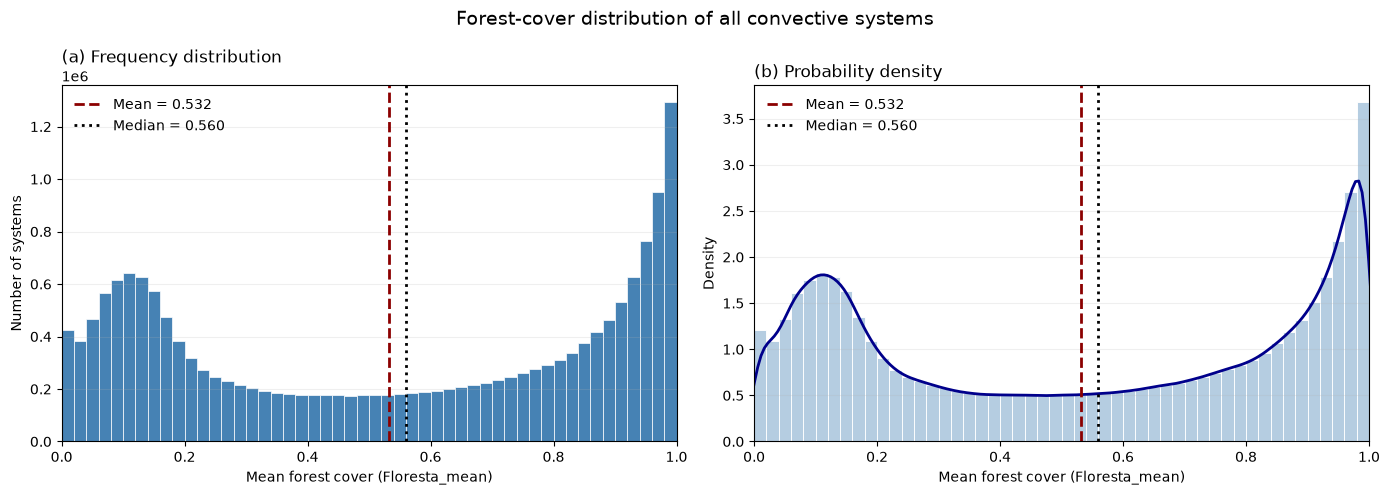

In [59]:

# ============================================================
# FREQUENCY + DENSITY DISTRIBUTIONS
# ALL SYSTEMS
# ============================================================

values = df_forest_all["forest_mean"].dropna()

mean_value = values.mean()
median_value = values.median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Frequency
axes[0].hist(
    values,
    bins=np.linspace(0, 1, 51),
    color="steelblue",
    edgecolor="white",
    linewidth=0.5
)

axes[0].axvline(
    mean_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.3f}"
)

axes[0].axvline(
    median_value,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_value:.3f}"
)

axes[0].set_xlabel("Mean forest cover (Floresta_mean)")
axes[0].set_ylabel("Number of systems")
axes[0].set_title("(a) Frequency distribution", loc="left")
axes[0].set_xlim(0, 1)
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.2)

# (b) Density
sns.histplot(
    values,
    bins=50,
    stat="density",
    color="steelblue",
    alpha=0.4,
    edgecolor="white",
    ax=axes[1]
)

sns.kdeplot(
    values,
    color="darkblue",
    linewidth=2,
    ax=axes[1]
)

axes[1].axvline(
    mean_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_value:.3f}"
)

axes[1].axvline(
    median_value,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_value:.3f}"
)

axes[1].set_xlabel("Mean forest cover (Floresta_mean)")
axes[1].set_ylabel("Density")
axes[1].set_title("(b) Probability density", loc="left")
axes[1].set_xlim(0, 1)
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Forest-cover distribution of all convective systems",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "forest_cover_frequency_distribution_all_systems.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
